In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import pearsonr,spearmanr,kendalltau
import seaborn as sns
import networkx as nx
import shapG.shapley as shapley
import time

import warnings
warnings.filterwarnings('ignore')

def crimedata_data_reader(filename='crimedata_processing.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['ViolentCrimesPerPop'],axis = 1)
    y = data['ViolentCrimesPerPop']
    return X, y

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score,f1_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')
def classification_kpi(G,S):
    """_summary_

    Args:
        G (nx.Graph): _description_
        S (list): list of nodes (list of columns)
    """
    cols = list(S)
    if len(cols) == 0:
        return 0
    else:
        X_train, X_test, y_train, y_test = train_test_split(X[cols], y, test_size=0.2, random_state=42)
        model = LinearRegression()

        model.fit(X_train,y_train)
        pred = model.predict(X_test)
#         auc = accuracy_score(y_test, lgb_pred)
        r2 = r2_score(y_test, pred)
        return r2

In [4]:
# import shapG and necessary libraries
import networkx as nx
import shapG.shapley as shapley
import shapG.plot as shapGplot
from shapG.utils import corr_generator, create_minimal_edge_graph
import time
s = time.time()

In [5]:
# explain the model
X, y = crimedata_data_reader('crimedata_processing.csv')
W = corr_generator(X)
A, W_new = create_minimal_edge_graph(W, version='v3')
G = nx.Graph(A)
shapley_value = shapley.shapG(G, m=3, f=classification_kpi, approximate_by_ratio=False)

100%|█████████████████████████████████████████| 121/121 [04:33<00:00,  2.26s/it]


In [6]:
e = time.time()
e-s

287.2883038520813

In [7]:
sorted_data = sorted(shapley_value.items(), key=lambda x: x[1], reverse=True)
sorted_data[:30]

[('assaultPerPop', 12.790090242256959),
 ('robbbPerPop', 8.573244019221262),
 ('PctKids2Par', 6.939968732895792),
 ('burglPerPop', 6.794379714377686),
 ('PctKidsBornNeverMar', 6.604996872434575),
 ('PctFam2Par', 6.0373235702591375),
 ('PctYoungKids2Par', 4.737127644129713),
 ('PctTeen2Par', 4.610859382537278),
 ('rapesPerPop', 4.5915695570136315),
 ('racePctWhite', 4.30640195060125),
 ('nonViolPerPop', 4.0893412686841435),
 ('murdPerPop', 3.8656201907514585),
 ('pctWInvInc', 3.734059390502478),
 ('PctPersOwnOccup', 3.439392428347969),
 ('FemalePctDiv', 3.32465447524063),
 ('pctWPubAsst', 3.2149922854067365),
 ('autoTheftPerPop', 3.0520892695285515),
 ('TotalPctDiv', 2.9834924288376925),
 ('PctNotHSGrad', 2.94296484565648),
 ('PctPersDenseHous', 2.8592173959272054),
 ('MalePctDivorce', 2.847420882627105),
 ('PctHousLess3BR', 2.832673468929233),
 ('PctHousOwnOcc', 2.64595556976874),
 ('PctHousNoPhone', 2.5491490495632454),
 ('racepctblack', 2.2076500113934268),
 ('PctPopUnderPov', 1.9170

In [8]:
sorted_data

[('assaultPerPop', 12.790090242256959),
 ('robbbPerPop', 8.573244019221262),
 ('PctKids2Par', 6.939968732895792),
 ('burglPerPop', 6.794379714377686),
 ('PctKidsBornNeverMar', 6.604996872434575),
 ('PctFam2Par', 6.0373235702591375),
 ('PctYoungKids2Par', 4.737127644129713),
 ('PctTeen2Par', 4.610859382537278),
 ('rapesPerPop', 4.5915695570136315),
 ('racePctWhite', 4.30640195060125),
 ('nonViolPerPop', 4.0893412686841435),
 ('murdPerPop', 3.8656201907514585),
 ('pctWInvInc', 3.734059390502478),
 ('PctPersOwnOccup', 3.439392428347969),
 ('FemalePctDiv', 3.32465447524063),
 ('pctWPubAsst', 3.2149922854067365),
 ('autoTheftPerPop', 3.0520892695285515),
 ('TotalPctDiv', 2.9834924288376925),
 ('PctNotHSGrad', 2.94296484565648),
 ('PctPersDenseHous', 2.8592173959272054),
 ('MalePctDivorce', 2.847420882627105),
 ('PctHousLess3BR', 2.832673468929233),
 ('PctHousOwnOcc', 2.64595556976874),
 ('PctHousNoPhone', 2.5491490495632454),
 ('racepctblack', 2.2076500113934268),
 ('PctPopUnderPov', 1.9170

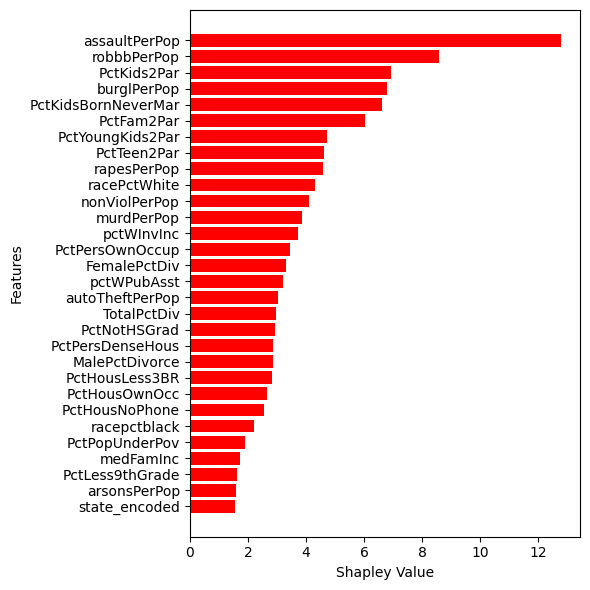

In [9]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 提取特征名称和权重（按权重从大到小排序）
data = [('assaultPerPop', 12.790090242256959),
 ('robbbPerPop', 8.573244019221262),
 ('PctKids2Par', 6.939968732895792),
 ('burglPerPop', 6.794379714377686),
 ('PctKidsBornNeverMar', 6.604996872434575),
 ('PctFam2Par', 6.0373235702591375),
 ('PctYoungKids2Par', 4.737127644129713),
 ('PctTeen2Par', 4.610859382537278),
 ('rapesPerPop', 4.5915695570136315),
 ('racePctWhite', 4.30640195060125),
 ('nonViolPerPop', 4.0893412686841435),
 ('murdPerPop', 3.8656201907514585),
 ('pctWInvInc', 3.734059390502478),
 ('PctPersOwnOccup', 3.439392428347969),
 ('FemalePctDiv', 3.32465447524063),
 ('pctWPubAsst', 3.2149922854067365),
 ('autoTheftPerPop', 3.0520892695285515),
 ('TotalPctDiv', 2.9834924288376925),
 ('PctNotHSGrad', 2.94296484565648),
 ('PctPersDenseHous', 2.8592173959272054),
 ('MalePctDivorce', 2.847420882627105),
 ('PctHousLess3BR', 2.832673468929233),
 ('PctHousOwnOcc', 2.64595556976874),
 ('PctHousNoPhone', 2.5491490495632454),
 ('racepctblack', 2.2076500113934268),
 ('PctPopUnderPov', 1.9170931354787437),
 ('medFamInc', 1.7225290550405004),
 ('PctLess9thGrade', 1.622064407651803),
 ('arsonsPerPop', 1.5931968078442211),
 ('state_encoded', 1.5704785681642381)]
labels, values = zip(*data)

plt.figure(figsize=(6, 6))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, values, color='r')
plt.gca().invert_yaxis()

plt.xlabel('Shapley Value')
plt.ylabel('Features')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('original_shapG_crime_LR.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()

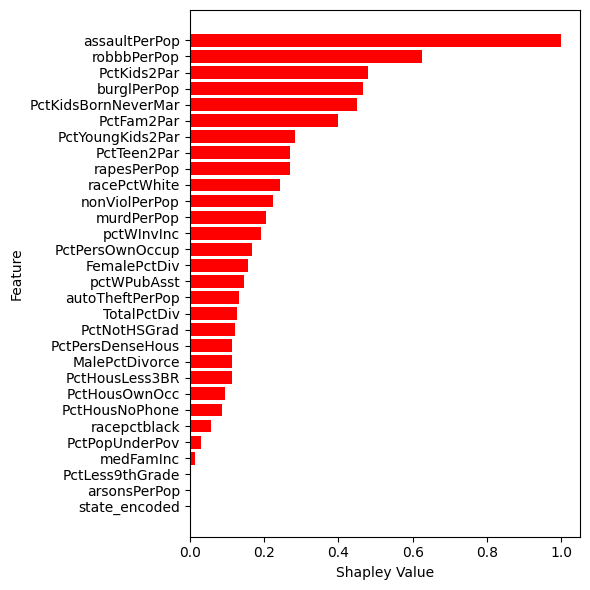

In [1]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# 提取特征名称和权重（按权重从大到小排序）
data = [('assaultPerPop', 12.790090242256959),
 ('robbbPerPop', 8.573244019221262),
 ('PctKids2Par', 6.939968732895792),
 ('burglPerPop', 6.794379714377686),
 ('PctKidsBornNeverMar', 6.604996872434575),
 ('PctFam2Par', 6.0373235702591375),
 ('PctYoungKids2Par', 4.737127644129713),
 ('PctTeen2Par', 4.610859382537278),
 ('rapesPerPop', 4.5915695570136315),
 ('racePctWhite', 4.30640195060125),
 ('nonViolPerPop', 4.0893412686841435),
 ('murdPerPop', 3.8656201907514585),
 ('pctWInvInc', 3.734059390502478),
 ('PctPersOwnOccup', 3.439392428347969),
 ('FemalePctDiv', 3.32465447524063),
 ('pctWPubAsst', 3.2149922854067365),
 ('autoTheftPerPop', 3.0520892695285515),
 ('TotalPctDiv', 2.9834924288376925),
 ('PctNotHSGrad', 2.94296484565648),
 ('PctPersDenseHous', 2.8592173959272054),
 ('MalePctDivorce', 2.847420882627105),
 ('PctHousLess3BR', 2.832673468929233),
 ('PctHousOwnOcc', 2.64595556976874),
 ('PctHousNoPhone', 2.5491490495632454),
 ('racepctblack', 2.2076500113934268),
 ('PctPopUnderPov', 1.9170931354787437),
 ('medFamInc', 1.7225290550405004),
 ('PctLess9thGrade', 1.622064407651803),
 ('arsonsPerPop', 1.5931968078442211),
 ('state_encoded', 1.5704785681642381)]
labels, values = zip(*data)

# 将权重转换为numpy数组
values = np.array(values).reshape(-1, 1)

# 使用MinMaxScaler进行归一化
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values).flatten()

# 绘制条形图
plt.figure(figsize=(6, 6))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, normalized_values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Feature')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()
plt.gca().invert_yaxis()

# 保存图像，确保DPI设置为300，并包括标签和边距
# plt.savefig('shapG_diabets_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

# plt.show()
# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('original_shapG_crime_LR_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()
